## Lab 5
## Name: Arnish Manwatkar
## Batch: C-C3
## Roll no: 38

In [2]:
from sklearn.metrics._plot.roc_curve import roc_curve
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import  (train_test_split,GridSearchCV,cross_val_score,StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ( accuracy_score,classification_report,confusion_matrix,roc_curve,f1_score,recall_score,precision_score,roc_auc_score)
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [3]:
df=pd.read_csv("diabetes.csv")
print(df)

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0              6      148             72             35        0  33.6   
1              1       85             66             29        0  26.6   
2              8      183             64              0        0  23.3   
3              1       89             66             23       94  28.1   
4              0      137             40             35      168  43.1   
..           ...      ...            ...            ...      ...   ...   
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
0                       0.627   50        1  
1                  

In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
df.shape

(768, 9)

In [9]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [10]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [13]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


### Univarient Analysis

<function matplotlib.pyplot.show(close=None, block=None)>

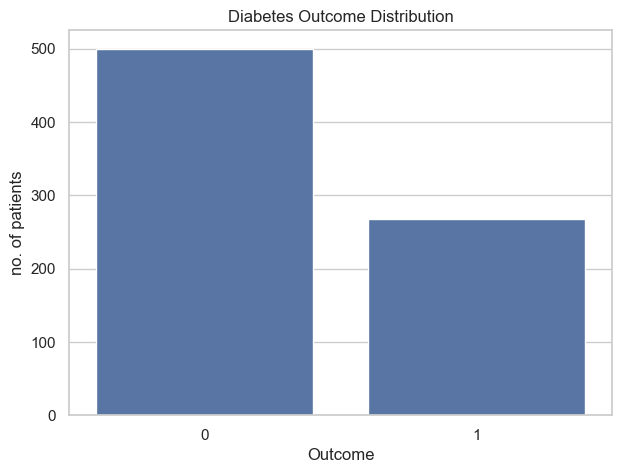

In [16]:
plt.figure(figsize=(7,5))
sns.countplot(x="Outcome",data=df)
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("no. of patients")
plt.show

### Bivarient analysis

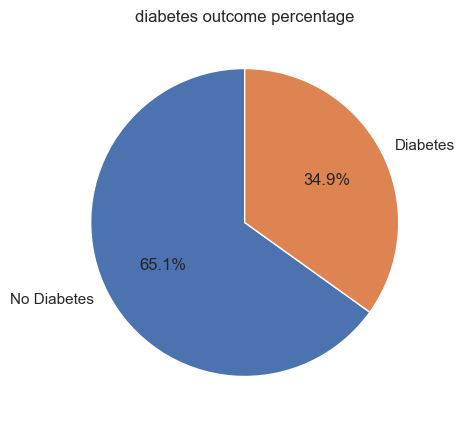

In [43]:
plt.figure(figsize=(7,5))
target_percentage = df['Outcome'].value_counts()
plt.pie(target_percentage,labels=["No Diabetes","Diabetes"],autopct="%1.1f%%",startangle=90)
plt.title("diabetes outcome percentage")
plt.show()

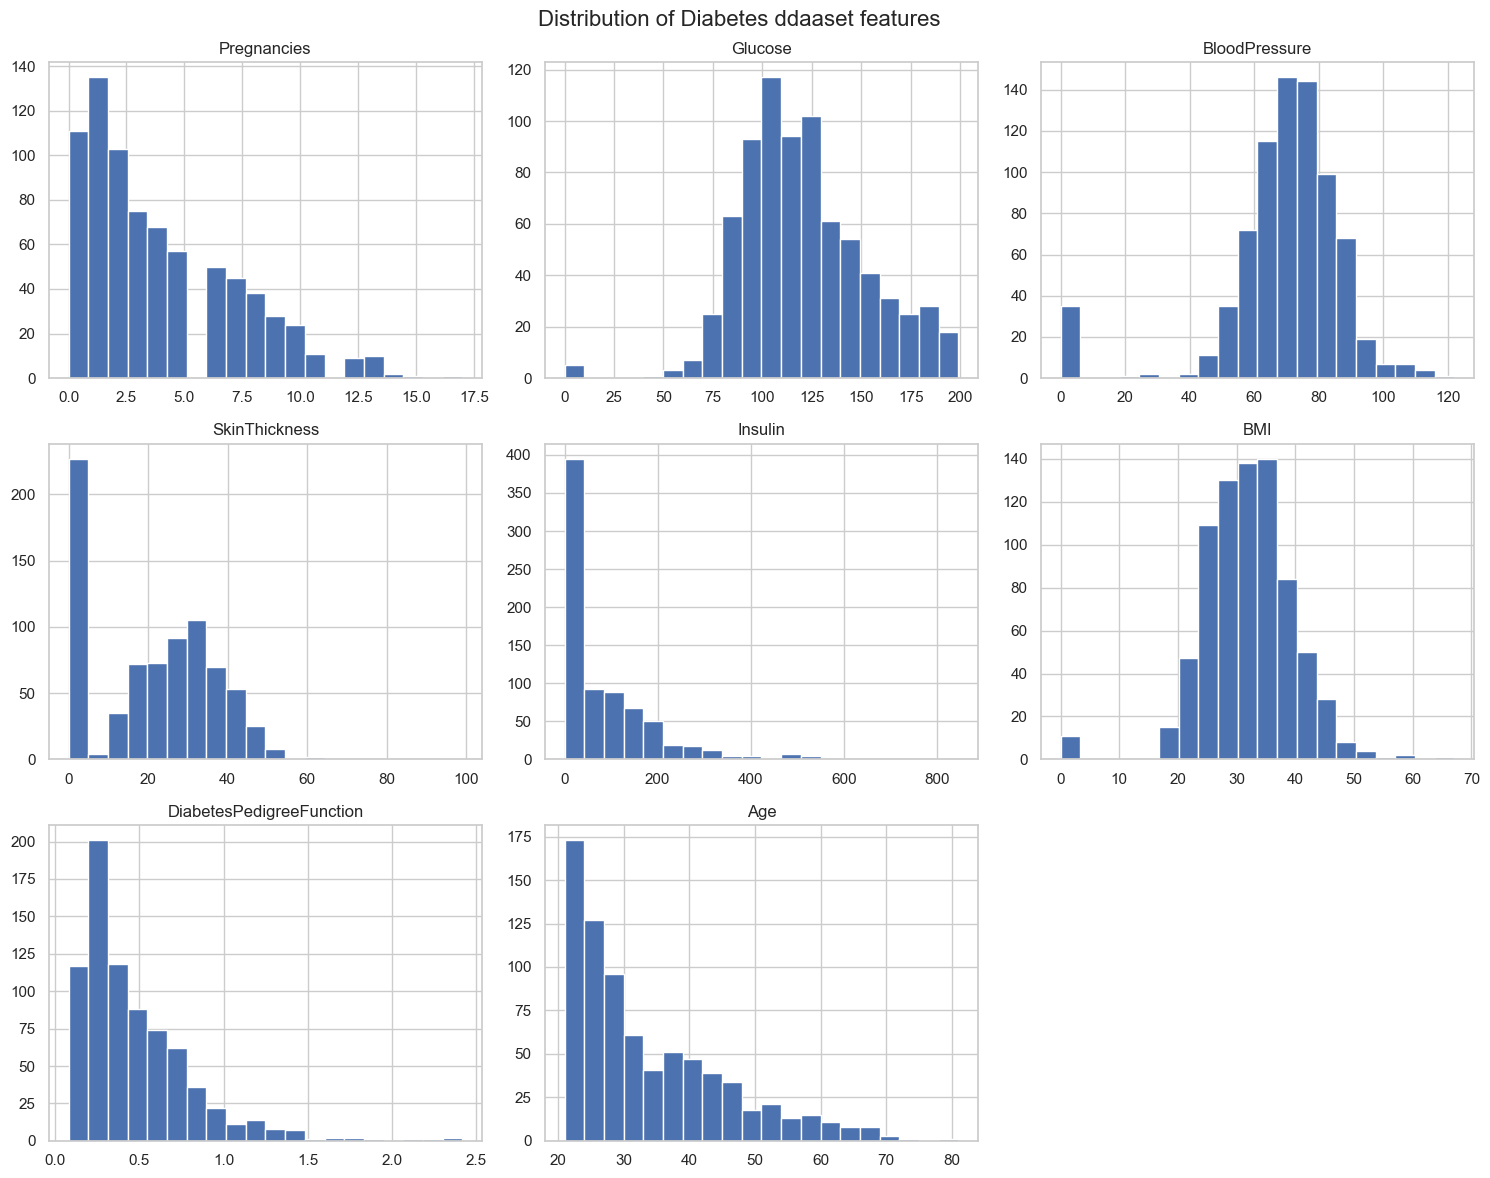

In [18]:
features = df.drop(columns ="Outcome").columns
df[features].hist(figsize=(15,12),bins=20)
plt.suptitle("Distribution of Diabetes ddaaset features ",fontsize=16)
plt.tight_layout()
plt.show()

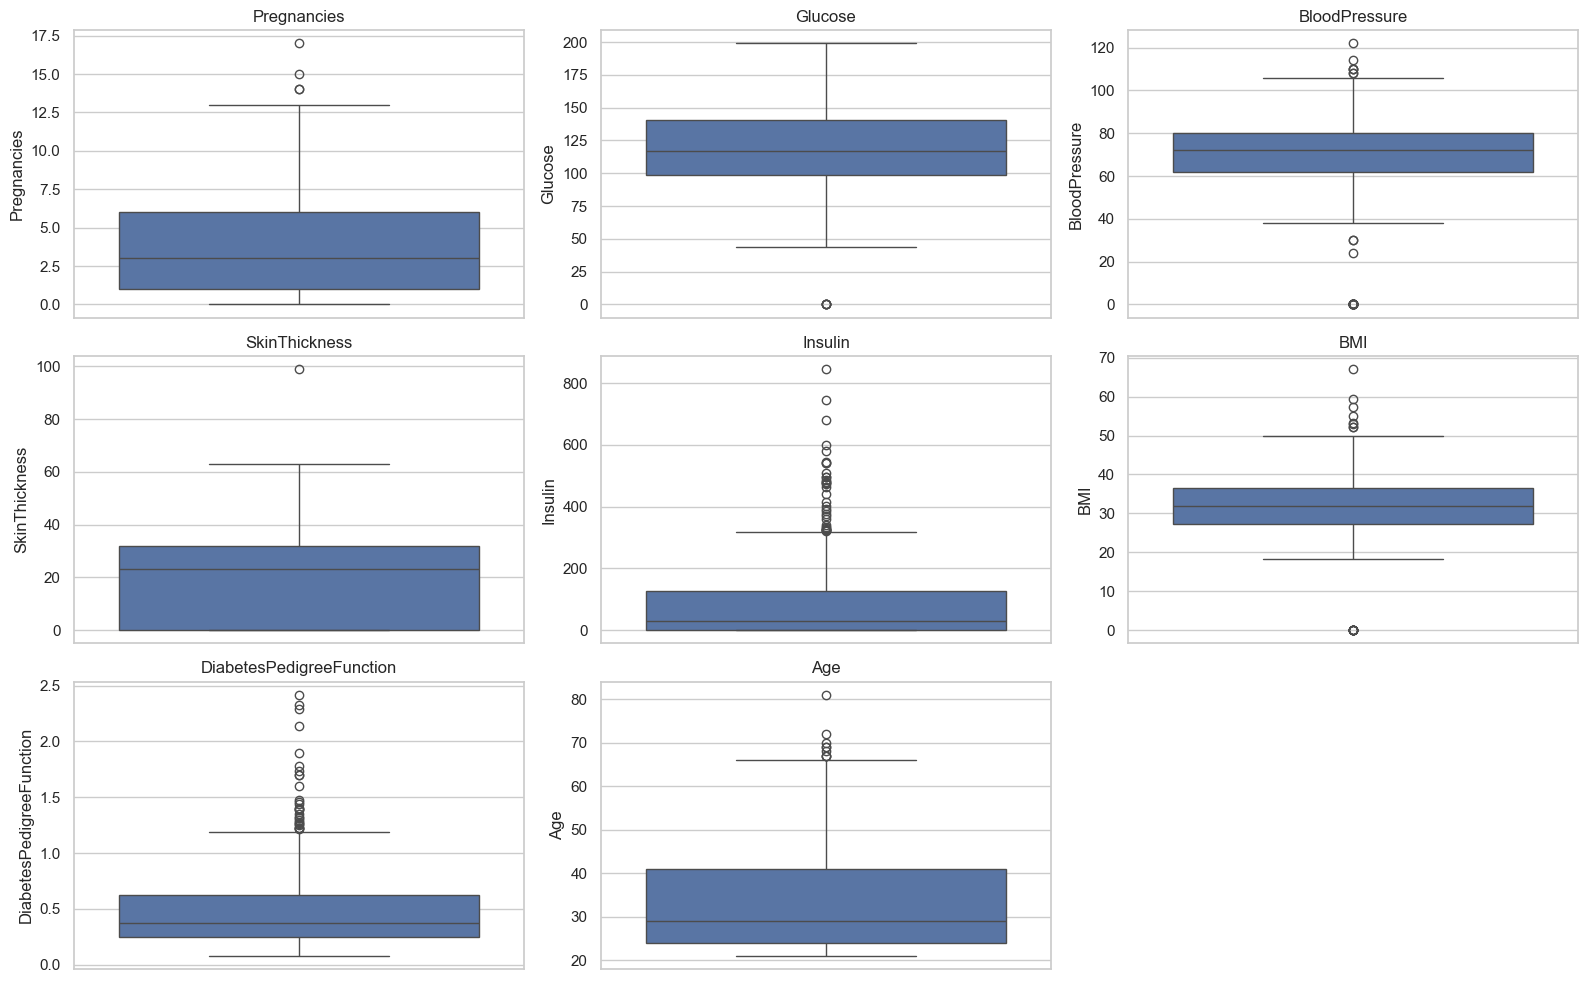

In [19]:
plt.figure(figsize=(16,10))
for i, col in enumerate(features,1):
    plt.subplot(3,3,i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [20]:
zero_columns = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
zero_counts = (df[zero_columns] ==  0).sum()
print("zero values:")
print(zero_counts)

zero values:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


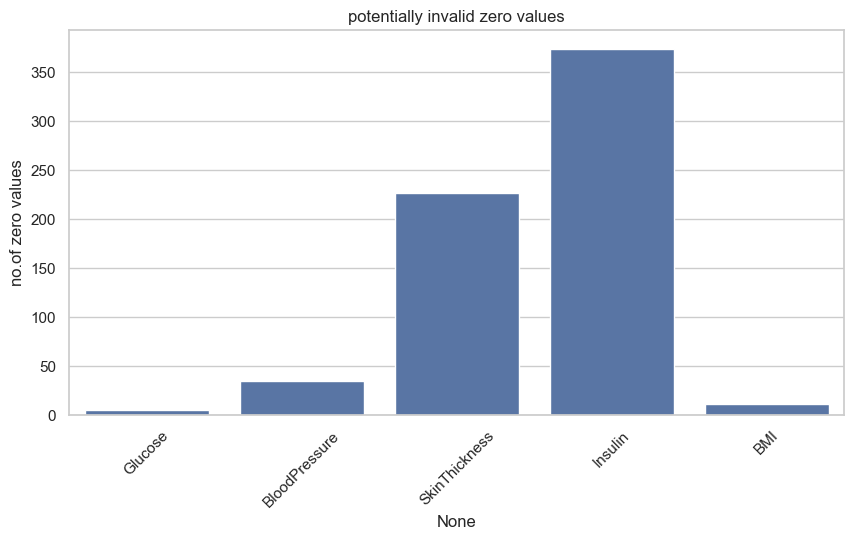

In [21]:
plt.figure(figsize=(10,5))
sns.barplot(x=zero_counts.index,y=zero_counts.values)
plt.xticks(rotation=45)
plt.ylabel("no.of zero values")
plt.title("potentially invalid zero values")
plt.show()

In [22]:
df_clean=df.copy()
df_clean[zero_columns] = df_clean[zero_columns].replace(0,np.nan)
print("missing values after replacing invalid zeros")
print(df_clean.isnull().sum())

missing values after replacing invalid zeros
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


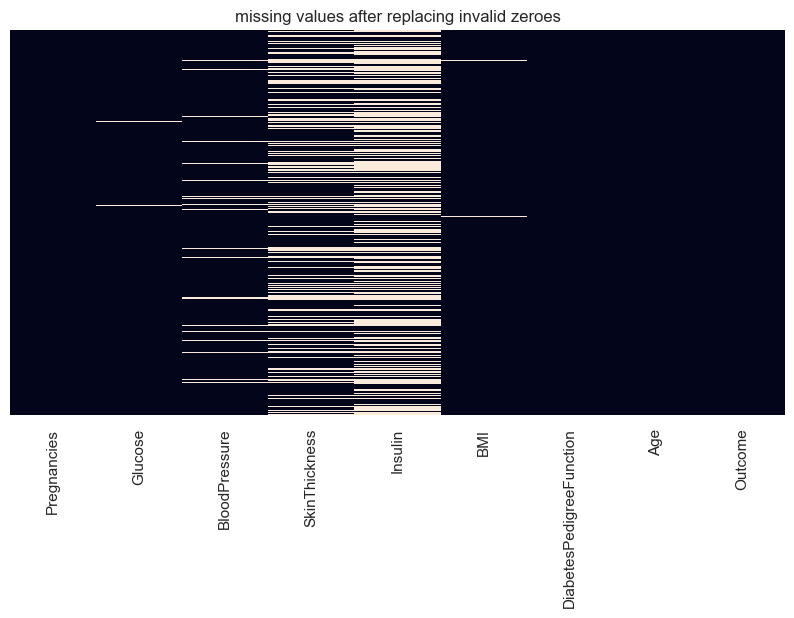

In [23]:
plt.figure(figsize=(10,5))
sns.heatmap(df_clean.isnull(),cbar=False,yticklabels=False)
plt.title("missing values after replacing invalid zeroes")
plt.show()

In [24]:
for col in zero_columns:
  df_clean[col] = df_clean[col].fillna(df_clean[col].median())
print("missing values after median imputation")
print(df_clean.isnull().sum())

missing values after median imputation
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


### Multivarient Analysis

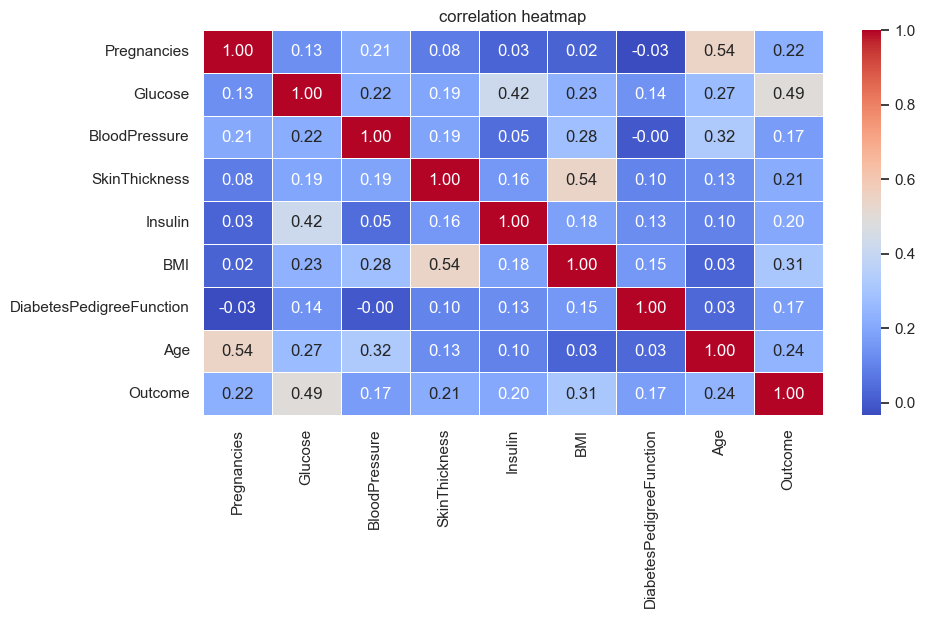

In [25]:
plt.figure(figsize=(10,5))
correlation = df_clean.corr()
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5)
plt.title("correlation heatmap")
plt.show()

In [26]:
target_corr = (df_clean.corr()["Outcome"].drop("Outcome").sort_values())
print(target_corr)

BloodPressure               0.165723
DiabetesPedigreeFunction    0.173844
Insulin                     0.203790
SkinThickness               0.214873
Pregnancies                 0.221898
Age                         0.238356
BMI                         0.312038
Glucose                     0.492782
Name: Outcome, dtype: float64


In [27]:
plt.figure(figsize=(8,6))

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

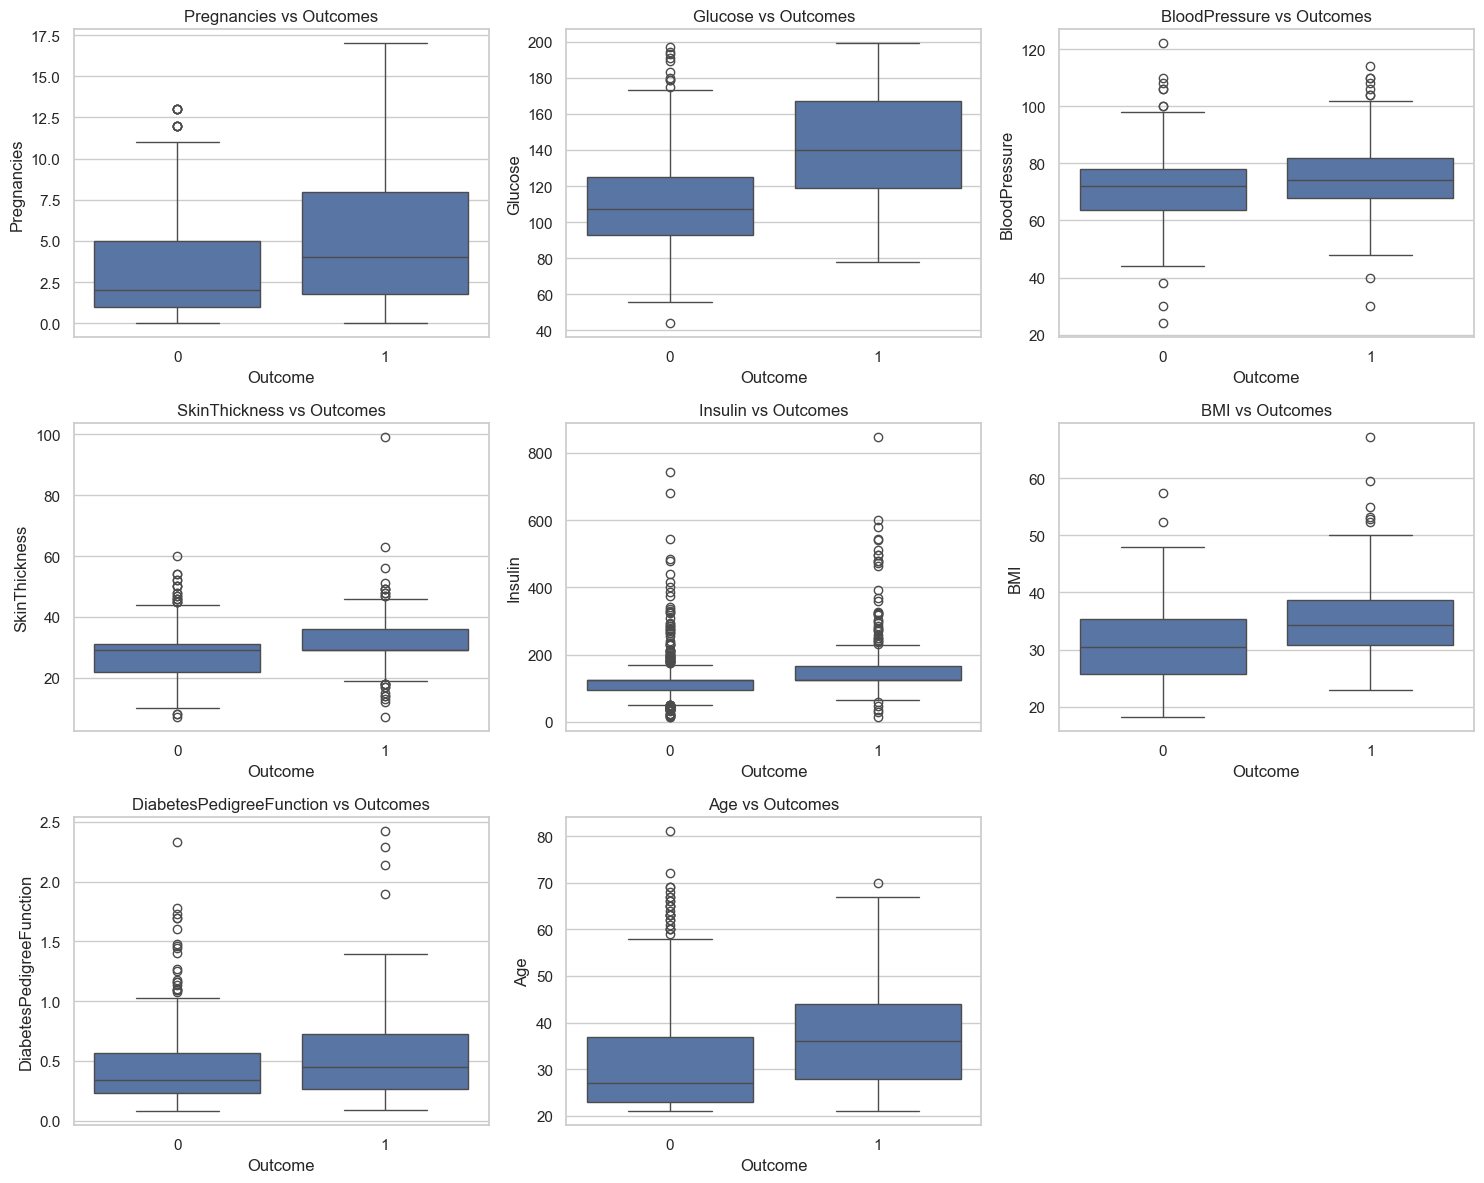

In [28]:
plt.figure(figsize=(15,12))
for i,col in enumerate(features,1):
  plt.subplot(3,3,i)
  sns.boxplot(y=col,x="Outcome",data=df_clean)
  plt.title(f"{col} vs Outcomes")
plt.tight_layout()
plt.show()

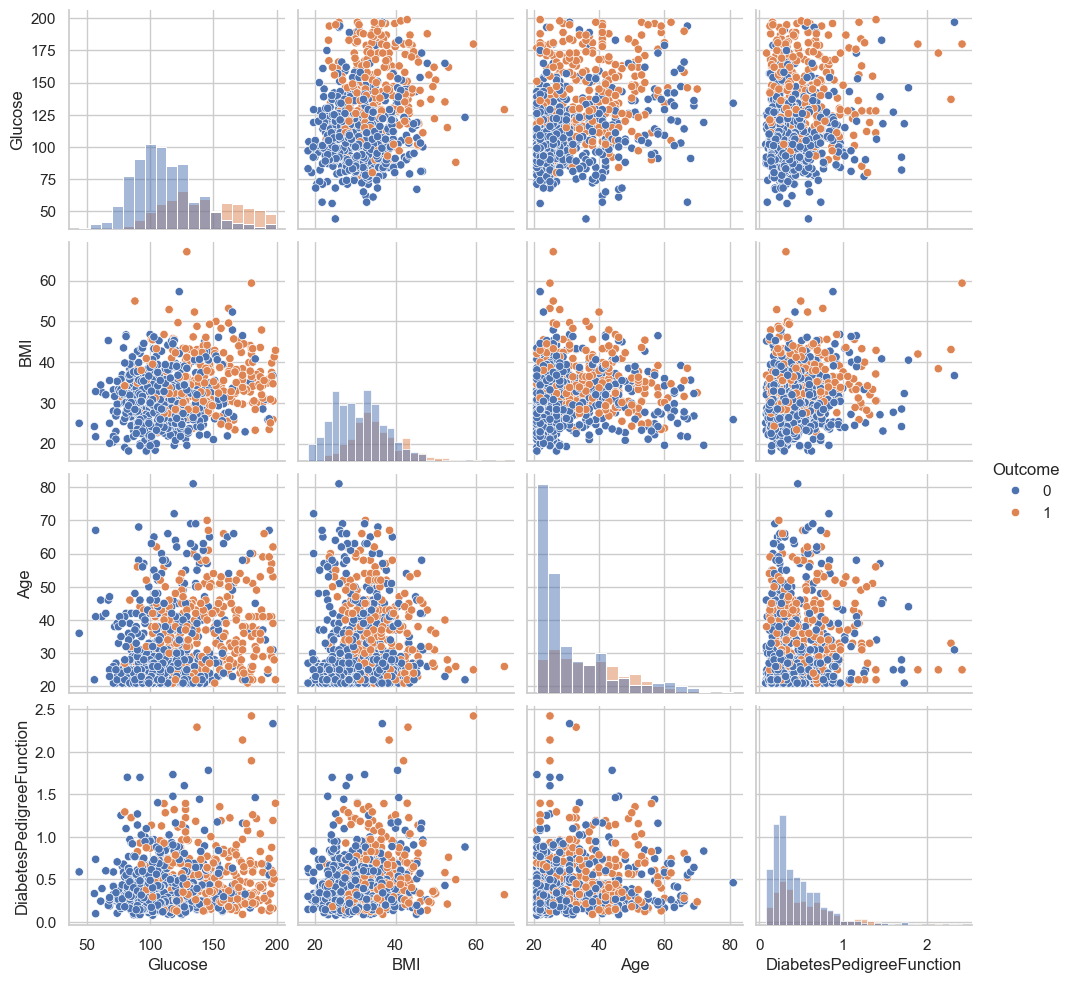

In [29]:
selected_features = ["Glucose","BMI","Age","DiabetesPedigreeFunction","Outcome"]
sns.pairplot(df_clean[selected_features],hue="Outcome",diag_kind ="hist")
plt.show()

### Model Training

In [30]:
X = df_clean.drop("Outcome",axis=1)
y = df_clean["Outcome"]
print("X shape:",X.shape)
print("y shape:",y.shape)

X shape: (768, 8)
y shape: (768,)


In [44]:
X_train , X_test ,y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify =y)
print("X_train shape:",X_train.shape[0])
print("X_test shape:",X_test.shape[0])

X_train shape: 614
X_test shape: 154


In [45]:
print("Training distribution")
print(y_train.value_counts(normalize=True))
print("Testing distribution")
print(y_test.value_counts(normalize=True))

Training distribution
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64
Testing distribution
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [32]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [33]:
X_test_scaled = scaler.fit_transform(X_test)
X_test_scaled = scaler.transform(X_test)

In [34]:
scaler.fit_transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [35]:
scaler.transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [36]:
comparison = pd.DataFrame({
    "Original mean":X_train.mean(),
    "Original std":X_train.std(),
    "Scaled mean":X_train_scaled.mean(),
    "Scaled std":X_train_scaled.std()
})
display(comparison)

,Original mean,Original std,Scaled mean,Scaled std
Pregnancies,3.819218,3.314148,-1.566789e-16,1.0
Glucose,121.671010,30.003794,-1.566789e-16,1.0
BloodPressure,72.140065,12.275119,-1.566789e-16,1.0
SkinThickness,29.042345,8.891855,-1.566789e-16,1.0
Insulin,137.705212,78.764767,-1.566789e-16,1.0
BMI,32.446743,6.824142,-1.566789e-16,1.0
DiabetesPedigreeFunction,0.477428,0.330300,-1.566789e-16,1.0
Age,33.366450,11.833438,-1.566789e-16,1.0


### KNN

In [37]:
K = 5
knn_classifier = KNeighborsClassifier(n_neighbors=K)
knn_classifier.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [38]:
y_pred = knn_classifier.predict(X_test_scaled)
print("Prediction")
print(y_pred[:20])

Prediction
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]


In [48]:
y_prob=knn_classifier.predict_proba(X_test_scaled)[:,1]
print(y_prob[:20])

[0.6 0.2 0.2 0.6 0.  0.2 0.2 0.8 0.  0.6 0.4 0.6 0.  0.  0.  0.6 0.8 0.
 1.  0.4]


In [49]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

In [50]:
print(precision)
print(recall)
print(f1)
print(accuracy)

0.7021276595744681
0.6111111111111112
0.6534653465346535
0.7727272727272727


In [41]:
print(classification_report(y_test, y_pred, target_names = ["No Diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.80      0.86      0.83       100
    Diabetes       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154



In [42]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[86 14]
 [21 33]]


<module 'matplotlib.pyplot' from 'C:\\Users\\nares\\miniconda3\\Lib\\site-packages\\matplotlib\\pyplot.py'>

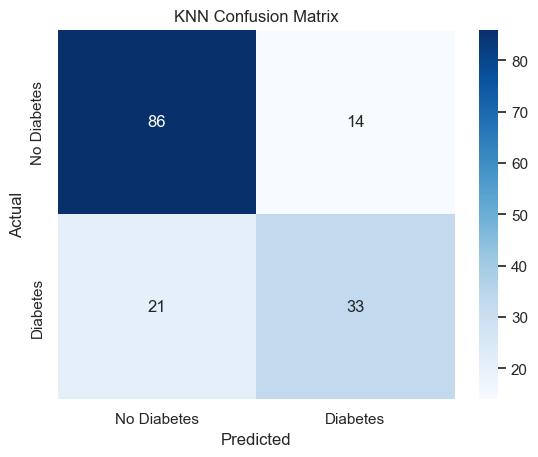

In [46]:
plt.figure()
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt

In [51]:
k_values = range(1,31)

train_accuracy = []
test_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    train_accuracy.append(model.score(X_train_scaled, y_train))
    test_accuracy.append(model.score(X_test_scaled, y_test))

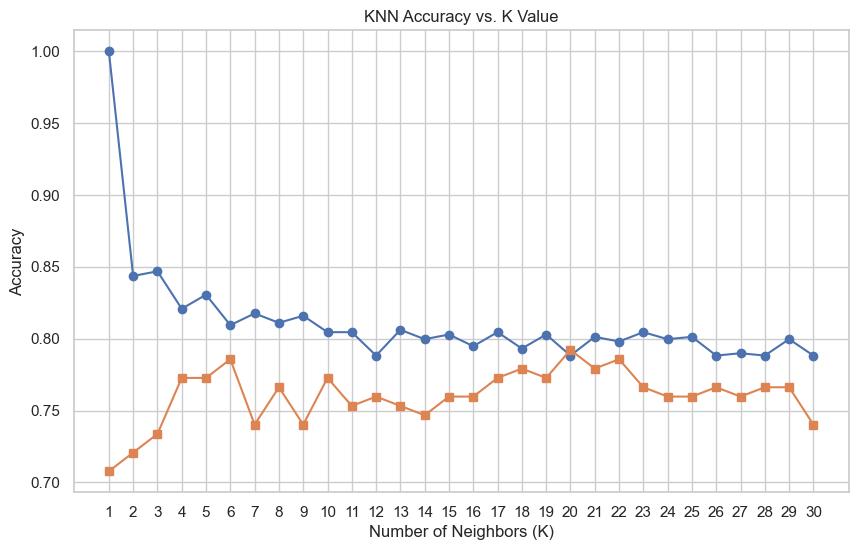

In [52]:
plt.figure(figsize=(10,6))
plt.plot(k_values, train_accuracy, marker = "o", label='Training Accuracy')
plt.plot(k_values, test_accuracy, marker = "s",label='Testing Accuracy')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs. K Value')
plt.xticks(k_values)
plt.show()

In [53]:
best_k_accuracy = k_values[np.argmax(test_accuracy)]

best_accuracy = max(test_accuracy)

print("Best K value:", best_k_accuracy)
print("Best Accuracy:", best_accuracy)

Best K value: 20
Best Accuracy: 0.7922077922077922


In [61]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle = True, random_state=42)

cv_scores = []
for k in range(1,31):
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring='accuracy')
    cv_scores.append(scores.mean())

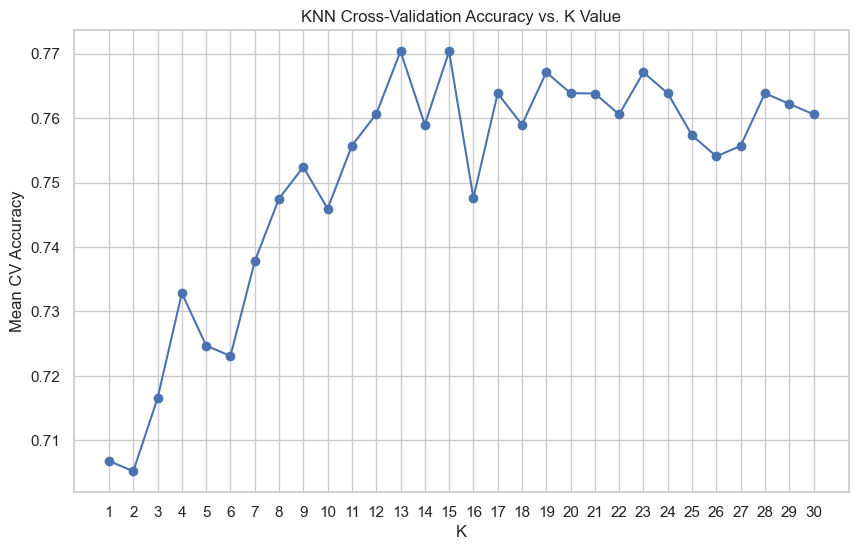

In [62]:
plt.figure(figsize = (10,6))

plt.plot(range(1,31), cv_scores, marker = 'o')
plt.xlabel('K')
plt.ylabel('Mean CV Accuracy')
plt.title('KNN Cross-Validation Accuracy vs. K Value')
plt.xticks(range(1,31))
plt.show()

In [63]:
best_k_cv = np.argmax(cv_scores) + 1

print("best k based on cv:", best_k_cv)
print("Best CV Accuracy:", max(cv_scores))

best k based on cv: 13
Best CV Accuracy: 0.7703718512594963


In [64]:
param_grid = {'n_neighbors': list(range(3,31,2)), "weights": ["uniform", "distance"],
              "metric": ["euclidean", "manhattan", "minkowski"],
              "p": [1,2]}

In [65]:
grid_search = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=param_grid, cv=5, scoring='accuracy', n_jobs = -1)
grid_search.fit(X_train_scaled, y_train)
print("Grid Search Complete")

Grid Search Complete


In [66]:
print("Best parameters:")
print(grid_search.best_params_)
print("Best accuracy:")
print(grid_search.best_score_)

Best parameters:
{'metric': 'euclidean', 'n_neighbors': 19, 'p': 1, 'weights': 'uniform'}
Best accuracy:
0.7769025723044115
